# Demo del SIG: inventario de medicamentos de la CSS

Este notebook lee las tablas que produce el pipeline y reproduce los indicadores principales del dashboard.

- **Fuente:** si existe la variable `MONGODB_URI`, lee de MongoDB Atlas (base `css_pharma`); si no, lee las tablas publicadas en la rama `data` del repositorio. No necesita credenciales para ejecutarse.
- **Uso en Colab:** `Entorno de ejecución → Ejecutar todas`. Para leer de MongoDB, guardar `MONGODB_URI` en *Secrets* de Colab.

Se responde la pregunta gerencial: **¿qué medicamentos están en riesgo y cómo redistribuirlos entre CDPA, CDDI y CDCH?**

In [1]:
import io, json, os
import pandas as pd
import requests
import matplotlib.pyplot as plt

GITHUB = "https://raw.githubusercontent.com/1ZH13/css-pharma-supply-analytics/data/processed/"

try:  # Colab Secrets, si existen
    from google.colab import userdata
    os.environ.setdefault("MONGODB_URI", userdata.get("MONGODB_URI") or "")
except Exception:
    pass

def _db():
    uri = os.environ.get("MONGODB_URI")
    if not uri:
        return None
    try:
        from pymongo import MongoClient
        cli = MongoClient(uri, serverSelectionTimeoutMS=8000)
        cli.admin.command("ping")
        return cli["css_pharma"]
    except Exception as e:
        print("MongoDB no disponible, se usa GitHub:", type(e).__name__)
        return None

DB = _db()
ORIGEN = "MongoDB Atlas" if DB is not None else "GitHub (rama data)"

def tabla(nombre):
    if DB is not None:
        return pd.DataFrame(list(DB[nombre].find({}, {"_id": 0})))
    r = requests.get(GITHUB + nombre + ".csv", timeout=60)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.content.decode("utf-8-sig")), dtype={"codigo": str})

def documento(nombre):
    r = requests.get(GITHUB + nombre + ".json", timeout=60)
    r.raise_for_status()
    return r.json()

print("Datos leídos desde:", ORIGEN)

Datos leídos desde: GitHub (rama data)


## 1. Indicadores del último mes

In [2]:
k = documento("kpi_resumen")
pd.Series({
    "Corte": k["periodo"],
    "Abastecimiento de los almacenes (%)": k["pct_abastecimiento"],
    "Renglones en cero": f'{k["renglones_en_cero"]} de {k["renglones"]}',
    "Críticos sin existencia": k["criticos_en_cero"],
    "Medicamentos en riesgo alto": k["riesgo_alto"],
    "Valor del inventario (B/.)": f'{k["valor_inventario"]:,.0f}',
    "Traslados sugeridos": k["transferencias_sugeridas"],
    "Valor de los traslados (B/.)": f'{k["valor_transferencias"]:,.0f}',
}).to_frame("valor")

,valor
Corte,2026-09
Abastecimiento de los almacenes (%),86.31
Renglones en cero,76 de 555
Críticos sin existencia,20
Medicamentos en riesgo alto,81
Valor del inventario (B/.),"42,929,830"
Traslados sugeridos,143
Valor de los traslados (B/.),"1,691,545"


## 2. Abastecimiento mensual de los almacenes (P2 y P5)

La CSS anuncia 90–96 %. La línea punteada marca la instalación de la Comisión de Desabastecimiento Crítico (octubre de 2025).

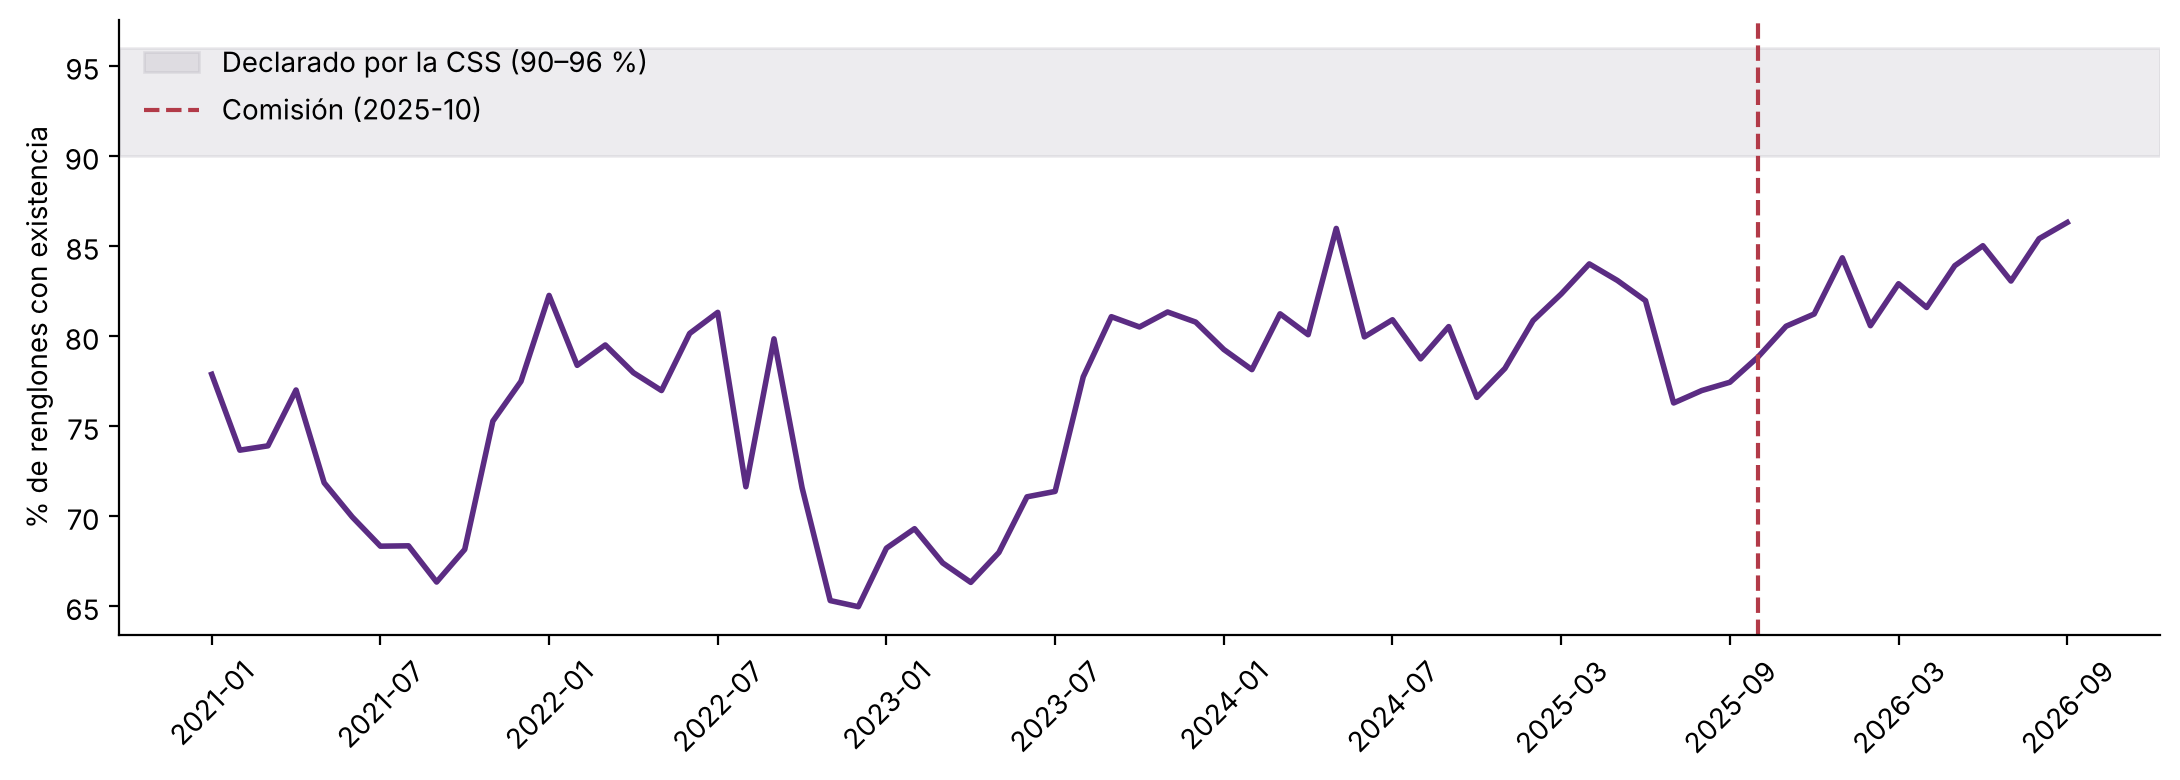

In [3]:
m = tabla("kpi_mensual").sort_values("periodo")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(m["periodo"], m["pct_abastecimiento"], color="#5B2C83", lw=2)
ax.axhspan(90, 96, color="#8A8494", alpha=.15, label="Declarado por la CSS (90–96 %)")
if "2025-10" in set(m["periodo"]):
    ax.axvline("2025-10", color="#B23A48", ls="--", label="Comisión (2025-10)")
ax.set_ylabel("% de renglones con existencia")
ax.set_xticks(m["periodo"][::6]); ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Medicamentos críticos en riesgo alto (P3)

In [4]:
r = tabla("riesgo_medicamentos")
r["critico"] = r["critico"].astype(str).str.lower().eq("true")
alto = r[(r["nivel_riesgo"] == "alto") & r["critico"]]
print(len(alto), "críticos en riesgo alto, por grupo:")
display(alto["categoria_critica"].value_counts().to_frame("medicamentos"))
alto.sort_values("puntaje_riesgo", ascending=False)[
    ["descripcion", "categoria_critica", "existencia_total", "cobertura_meses", "puntaje_riesgo", "motivos"]].head(10)

50 críticos en riesgo alto, por grupo:


,medicamentos
categoria_critica,
Oncológicos,16
Cardiovascular,11
Asma y EPOC,5
Antivirales (incluye VIH),4
Terapia hormonal oncológica,3
Antiepilépticos,3
Antitrombóticos,3
Inmunosupresores,2
Insulinas,1


,descripcion,categoria_critica,existencia_total,cobertura_meses,puntaje_riesgo,motivos
0,"PROPRANOLOL CLORHIDRATO, 10MG, TABLETA, V.O.",Cardiovascular,0.0,0.0,80,sin existencia; 12 de 12 meses en cero; crític...
1,"BICALUTAMIDA, 50MG, TABLETA, V.O.",Terapia hormonal oncológica,4620.0,0.2,76,cobertura 0.2 meses; 8 de 12 meses en cero; ex...
2,"MELFALANO 2mg, tableta, V.O.",Oncológicos,0.0,0.0,75,sin existencia; 12 de 12 meses en cero; crític...
3,"DOXORUBICINA CLORHIDRATO 10mg-50mg, polvo liof...",Oncológicos,0.0,0.0,75,sin existencia; 12 de 12 meses en cero; crític...
4,"ETOPÓSIDO 20mg/ml, solución, I.V.",Oncológicos,0.0,0.0,75,sin existencia; 12 de 12 meses en cero; crític...
5,"LAMIVUDINA 10mg/ml, solución, frasco, 240-300m...",Antivirales (incluye VIH),0.0,0.0,75,sin existencia; 12 de 12 meses en cero; crític...
6,"PROPRANOLOL CLORHIDRATO 1mg/ml, solución, I.V.",Cardiovascular,0.0,0.0,74,sin existencia; 2 de 12 meses en cero; existen...
7,"CLONAZEPAM 2mg, tableta, V.O.",Antiepilépticos,0.0,0.0,73,sin existencia; 4 de 12 meses en cero; existen...
8,"IMATINIB MESILATO 100mg, cápsula o tableta, V.O.",Oncológicos,0.0,0.0,73,sin existencia; 4 de 12 meses en cero; existen...
9,"ASPARAGINASA 10,000UI, polvo liofilizado, I.V.",Oncológicos,0.0,0.0,73,sin existencia; 4 de 12 meses en cero; existen...


## 4. Redistribución entre centros (P4)

Un centro recibe si tiene menos de 1 mes de cobertura y cede si tiene más de 4; el objetivo es dejar 2 meses.

In [5]:
t = tabla("redistribucion")
resumen = t.groupby(["desde", "hacia"]).agg(traslados=("codigo", "size"), valor=("valor", "sum")).reset_index()
resumen["valor"] = resumen["valor"].map("B/. {:,.0f}".format)
print(f"{len(t)} traslados sugeridos por B/. {t['valor'].sum():,.0f}")
resumen

143 traslados sugeridos por B/. 1,691,545


,desde,hacia,traslados,valor
0,CDCH,CDDI,7,"B/. 65,732"
1,CDCH,CDPA,28,"B/. 496,133"
2,CDDI,CDCH,8,"B/. 71,079"
3,CDDI,CDPA,19,"B/. 329,779"
4,CDPA,CDCH,36,"B/. 601,401"
5,CDPA,CDDI,45,"B/. 127,421"


## 5. Medicamentos “fantasma” (P6)

Siguen publicados en el catálogo, pero llevan 12 meses seguidos sin existencia.

In [6]:
f = tabla("p6_fantasmas")
print(len(f), "medicamentos fantasma")
f[[x for x in ["descripcion", "categoria_critica", "ultimo_mes_con_existencia"] if x in f.columns]]

23 medicamentos fantasma


,descripcion,categoria_critica,ultimo_mes_con_existencia
0,"ETOPÓSIDO 20mg/ml, solución, I.V.",Oncológicos,2022-12
1,"MELFALANO 2mg, tableta, V.O.",Oncológicos,2024-08
2,"LAMIVUDINA 10mg/ml, solución, frasco, 240-300m...",Antivirales (incluye VIH),2025-01
3,"PROPRANOLOL CLORHIDRATO, 10MG, TABLETA, V.O.",Cardiovascular,2025-03
4,"DOXORUBICINA CLORHIDRATO 10mg-50mg, polvo liof...",Oncológicos,2025-04
5,"SULPIRIDA 200mg, cápsula o tableta, V.O.",NaN,2022-08
6,"DAPSONA 100mg, tableta, V.O.",NaN,2023-07
7,"OXICODONA CLORHIDRATO 10mg, tableta de liberac...",NaN,2024-05
8,"CLORANFENICOL, 0.5%, GOTAS, SOLUCIÓN, FRASCO 5...",NaN,2024-05
9,"BIPERIDENO LACTATO 5mg/ml, solución, I.M., I.V.",NaN,2024-08


## Conclusión

Los mismos datos alimentan el dashboard en Streamlit (https://css-medicamentos-panama.streamlit.app) y el reporte de Power BI (`dashboard/powerbi`). El pipeline los actualiza automáticamente el día 3 de cada mes.